# 전국 화재 데이터로 화재 원인 예측하기

- 데이터: **소방청_화재발생 정보** — 공공데이터포털(data.go.kr), 이용허락범위 제한 없음
  - 2020년 1월 ~ 2024년 12월 전국에서 발생한 **실제 화재 191,510건**
  - 발생 일시, 지역, 화재 유형, 장소(대·중·소분류), 발화 원인, 인명·재산 피해가 화재 1건마다 기록됨
  - 원본(cp949 CSV)을 `make_dataset.py`로 영어 컬럼명 + 엑셀에서 열리는 CSV로 바꿔 사용
  - 분석에 쓰지 않는 3개 컬럼(시군구, 부동산·동산 피해 세부)은 빼서 GitHub 업로드 제한(25MB) 아래로 맞춤 (행은 그대로)
- 목표: 화재가 **언제(월·시간·요일), 어디서(지역·장소), 어떤 종류로** 났는지만으로 **발화 원인**(부주의 / 전기적 요인 / 기계적 요인 / 기타)을 예측하고,
  시기·장소별로 어떤 원인을 조심해야 하는지 해석
- 활용: 원인 조사가 끝나기 전 **우선 점검할 방향** 제시, 원인이 '미상'으로 남은 화재의 원인 추정, 시기·장소별 **맞춤 예방 홍보**

In [1]:
# ── 공통 설정 ──
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (윈도우 기본 '맑은 고딕'), 마이너스 기호 깨짐 방지
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 결과 재현을 위해 난수 시드를 42로 고정
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 경로 설정: 데이터는 dataset 폴더, 발표용 그림은 outputs 폴더에 저장
DATA_PATH = os.path.join('dataset', 'fire_2020_2024.csv')
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)

# 그래프에서 원인별 색을 항상 같게 쓰기 위한 설정
CLASSES = ['부주의', '전기적 요인', '기계적 요인', '기타']
COLORS = {'부주의': '#f58518', '전기적 요인': '#4c78a8', '기계적 요인': '#54a24b', '기타': '#9aa5b1'}

## 1. 데이터 확인

In [2]:
# 파일이 없으면 여기서 멈추도록 에러를 발생시킴
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f'{DATA_PATH} 파일이 없습니다. 소방청 원본 CSV를 dataset/raw 폴더에 넣고 make_dataset.py를 먼저 실행해 주세요.')

# utf-8-sig: 엑셀용으로 저장한 파일 맨 앞의 표시(BOM)를 빼고 읽음
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig', parse_dates=['datetime'])
print('데이터 크기(행, 열):', df.shape)
print('기간:', df['datetime'].min(), '~', df['datetime'].max())
df.head()

데이터 크기(행, 열): (191510, 12)
기간: 2020-01-01 00:03:00 ~ 2024-12-31 23:54:00


,datetime,sido,fire_type,cause,cause_detail,casualties,deaths,injuries,damage,place_1,place_2,place_3
0,2020-01-01 00:03:00,전북특별자치도,"건축,구조물",부주의,기타(부주의),0,0,0,171,생활서비스,음식점,"치킨,족발"
1,2020-01-01 00:33:00,서울특별시,기타(쓰레기 화재등),부주의,담배꽁초,0,0,0,326,기타,야외,쓰레기
2,2020-01-01 00:35:00,경상북도,기타(쓰레기 화재등),부주의,담배꽁초,0,0,0,0,기타,야외,기타야외
3,2020-01-01 00:40:00,충청북도,"자동차,철도차량",기계적 요인,"과열, 과부하",0,0,0,2640,"자동차,철도차량",자동차,승용자동차
4,2020-01-01 00:59:00,부산광역시,"자동차,철도차량",미상,미상,0,0,0,7904,"자동차,철도차량",자동차,오토바이


In [3]:
# 컬럼 자료형과 결측치, 중복 확인
df.info()
print()
print('결측치 개수 합계:', df.isnull().sum().sum())
print('완전히 같은 행:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 191510 entries, 0 to 191509
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   datetime      191510 non-null  datetime64[us]
 1   sido          191510 non-null  str           
 2   fire_type     191510 non-null  str           
 3   cause         191510 non-null  str           
 4   cause_detail  191510 non-null  str           
 5   casualties    191510 non-null  int64         
 6   deaths        191510 non-null  int64         
 7   injuries      191510 non-null  int64         
 8   damage        191510 non-null  int64         
 9   place_1       191510 non-null  str           
 10  place_2       191510 non-null  str           
 11  place_3       191510 non-null  str           
dtypes: datetime64[us](1), int64(4), str(7)
memory usage: 35.3 MB

결측치 개수 합계: 0
완전히 같은 행: 2


### 1-2. 컬럼 설명

| 컬럼 | 원본 항목명 | 의미 |
|---|---|---|
| datetime | 화재발생년원일 | 발생 일시 (분 단위) |
| sido | 시도 | 발생 지역 (17개 시도) |
| fire_type | 화재유형 | 건축·구조물, 자동차·철도차량, 임야, 기타(쓰레기 화재 등) 등 6종 |
| **cause** | 발화요인대분류 | **예측 대상**: 부주의, 전기적 요인, 기계적 요인, 방화, 미상 등 12종 |
| cause_detail | 발화요인소분류 | 세부 원인 (담배꽁초, 음식물 조리중, 과부하 등) — **원인 조사 결과이므로 입력에 쓰지 않음** |
| casualties / deaths / injuries | 인명피해 소계 / 사망 / 부상 | 명 |
| damage | 재산피해 소계 | 천원 |
| place_1 / place_2 / place_3 | 장소 대·중·소분류 | 예: 생활서비스 > 음식점 > 치킨·족발 |

In [4]:
# 범주형 컬럼별 종류 수
for col in ['sido', 'fire_type', 'cause', 'place_1', 'place_2', 'place_3']:
    print(f'{col}: {df[col].nunique()}종')
print()
print(df['cause'].value_counts().to_string())

sido: 17종
fire_type: 6종
cause: 12종
place_1: 15종
place_2: 50종
place_3: 364종

cause
부주의         90849
전기적 요인      49759
기계적 요인      19694
미상          16508
화학적 요인       3698
기타           2557
교통사고         2113
방화           1771
방화의심         1732
자연적인 요인      1321
제품결함          801
가스누출(폭발)      707


## 2. 탐색적 데이터 분석(EDA)

### 2-1. 원인 그룹 정하기
12종 중 일부는 건수가 매우 적어서(가스누출 707건, 제품결함 801건 등) 그대로 예측하기 어렵습니다.
건수가 많은 3개(부주의·전기적·기계적 요인)는 그대로 두고, 나머지는 **'기타'**로 묶습니다.
**'미상'**(원인을 밝히지 못한 화재)은 정답이 없으므로 학습에서 빼고, 5-2에서 모델로 원인을 추정해 봅니다.

In [5]:
def group_cause(c):
    return c if c in ['부주의', '전기적 요인', '기계적 요인', '미상'] else '기타'

df['cause_group'] = df['cause'].apply(group_cause)
print(df['cause_group'].value_counts().to_string())
print()
print('기타에 묶인 원인:', sorted(df.loc[df['cause_group'] == '기타', 'cause'].unique()))

# EDA·모델링 모두 원인을 아는 화재만 사용
known = df[df['cause_group'] != '미상'].copy()
known['month'] = known['datetime'].dt.month
known['hour'] = known['datetime'].dt.hour
print(f'\n원인을 아는 화재: {len(known):,}건 / 원인 미상: {(df["cause_group"] == "미상").sum():,}건 ({(df["cause_group"] == "미상").mean():.1%})')

cause_group
부주의       90849
전기적 요인    49759
기계적 요인    19694
미상        16508
기타        14700

기타에 묶인 원인: ['가스누출(폭발)', '교통사고', '기타', '방화', '방화의심', '자연적인 요인', '제품결함', '화학적 요인']



원인을 아는 화재: 175,002건 / 원인 미상: 16,508건 (8.6%)


### 2-2. 계절(월)에 따라 원인이 달라질까?

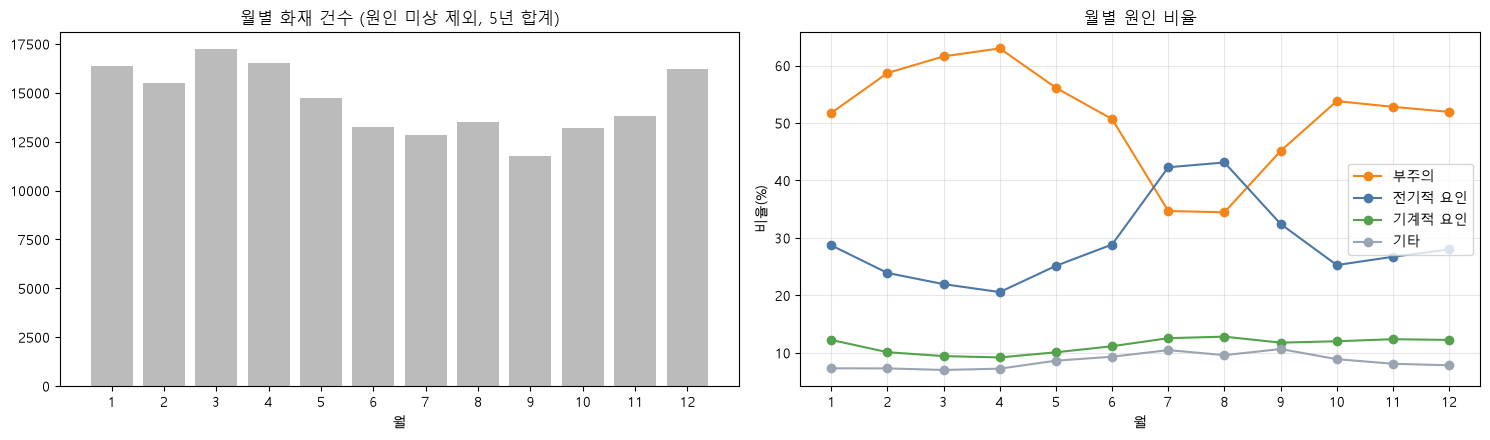

cause_group   부주의  전기적 요인  기계적 요인    기타
month                                  
1            51.8    28.7    12.2   7.3
2            58.7    23.9    10.1   7.3
3            61.6    22.0     9.4   7.0
4            63.0    20.6     9.2   7.2
5            56.1    25.1    10.1   8.6
6            50.7    28.8    11.2   9.3
7            34.7    42.3    12.6  10.5
8            34.5    43.1    12.8   9.6
9            45.1    32.4    11.8  10.7
10           53.8    25.3    12.0   8.9
11           52.8    26.7    12.4   8.1
12           51.9    28.0    12.2   7.8


In [6]:
by_month = pd.crosstab(known['month'], known['cause_group'], normalize='index')[CLASSES] * 100
counts = known.groupby('month').size()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(counts.index, counts.values, color='#bbbbbb')
axes[0].set_title('월별 화재 건수 (원인 미상 제외, 5년 합계)')
axes[0].set_xlabel('월')
axes[0].set_xticks(range(1, 13))
for c in CLASSES:
    axes[1].plot(by_month.index, by_month[c], marker='o', color=COLORS[c], label=c)
axes[1].set_title('월별 원인 비율')
axes[1].set_xlabel('월')
axes[1].set_ylabel('비율(%)')
axes[1].set_xticks(range(1, 13))
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '01_월별_화재건수_원인비율.png'), dpi=200, bbox_inches='tight')
plt.show()

print(by_month.round(1).to_string())

**관찰:** 계절에 따라 원인 구성이 뚜렷하게 바뀝니다. **7~8월에는 전기적 요인이 42~43%로 부주의(약 35%)보다 많아지고**, **3~4월에는 부주의가 62~63%로 가장 높습니다.**
여름에는 에어컨·선풍기 등 전기 사용이 늘고, 봄에는 건조한 날씨에 쓰레기·논밭두렁 태우기와 담배꽁초 화재가 많기 때문으로 보입니다. 월은 원인을 구분하는 데 쓸모 있는 정보입니다.

### 2-3. 하루 중 시간대에 따라 원인이 달라질까?

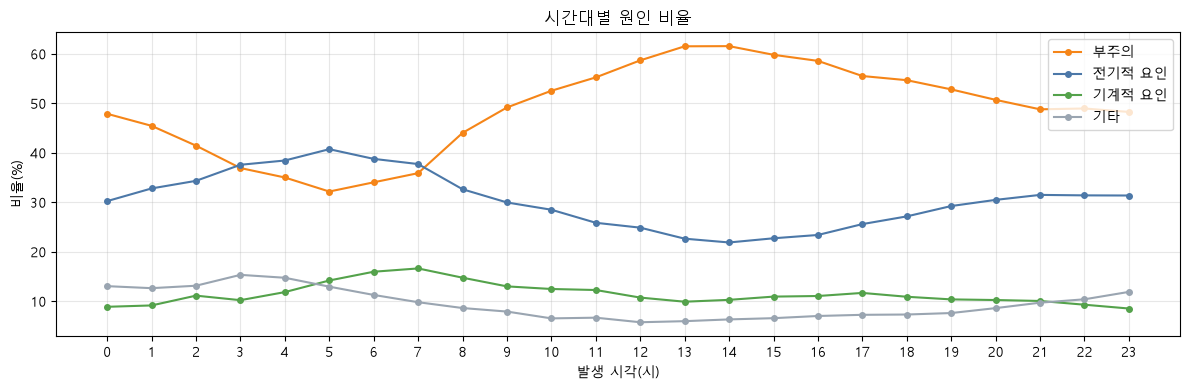

cause_group   부주의  전기적 요인  기계적 요인    기타
hour                                   
3            36.9    37.6    10.2  15.3
9            49.2    30.0    13.0   7.9
14           61.5    21.9    10.3   6.3
19           52.8    29.2    10.4   7.6
23           48.2    31.4     8.5  11.9


In [7]:
by_hour = pd.crosstab(known['hour'], known['cause_group'], normalize='index')[CLASSES] * 100
fig, ax = plt.subplots(figsize=(12, 4))
for c in CLASSES:
    ax.plot(by_hour.index, by_hour[c], marker='o', markersize=4, color=COLORS[c], label=c)
ax.set_xticks(range(0, 24))
ax.set_xlabel('발생 시각(시)')
ax.set_ylabel('비율(%)')
ax.set_title('시간대별 원인 비율')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '02_시간대별_원인비율.png'), dpi=200, bbox_inches='tight')
plt.show()

print(by_hour.loc[[3, 9, 14, 19, 23]].round(1).to_string())

**관찰:** 오후 2시에는 부주의가 61.5%로 가장 높지만, **새벽 3시에는 전기적 요인(37.6%)이 부주의(36.9%)와 비슷해지고 기타(15.3%)도 늘어납니다.**
사람이 활동하는 낮에는 부주의 화재가 많고, 사람이 잠든 새벽에는 전기 설비나 방화 등 사람의 행동과 무관한 원인의 비중이 커집니다.

### 2-4. 장소에 따라 원인이 달라질까?

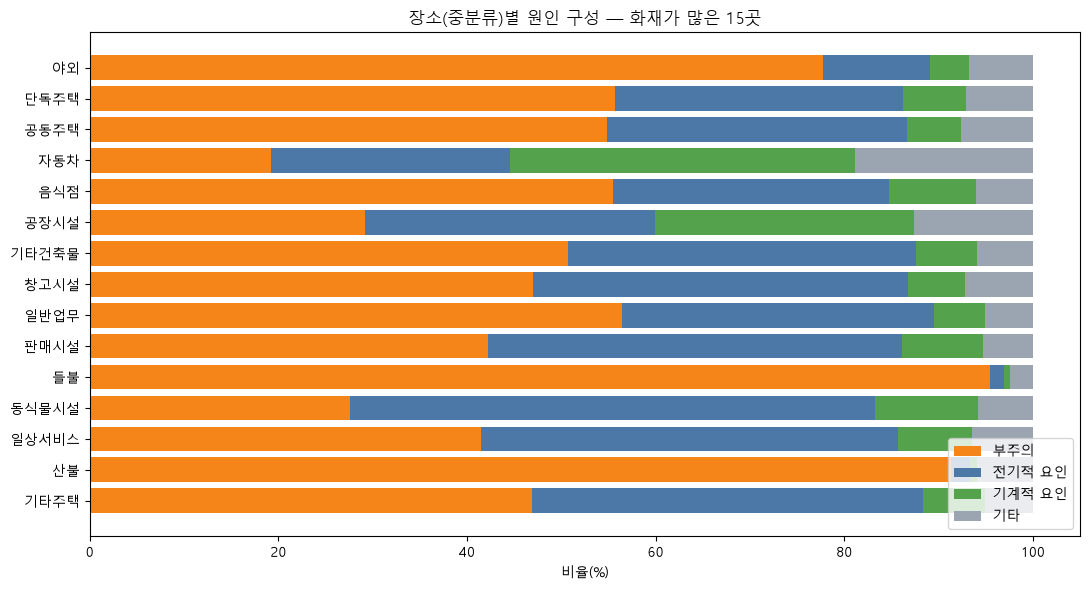

cause_group   부주의  전기적 요인  기계적 요인    기타
place_2                                
야외           77.8    11.3     4.1   6.8
단독주택         55.7    30.5     6.7   7.0
공동주택         54.9    31.8     5.7   7.6
자동차          19.2    25.4    36.6  18.8
음식점          55.4    29.3     9.3   6.0
공장시설         29.2    30.8    27.4  12.6
기타건축물        50.7    37.0     6.4   6.0
창고시설         47.0    39.7     6.0   7.2
일반업무         56.4    33.1     5.3   5.1
판매시설         42.3    43.9     8.6   5.3
들불           95.4     1.5     0.6   2.5
동식물시설        27.6    55.7    10.9   5.8
일상서비스        41.5    44.2     7.8   6.5
산불           91.3     2.1     0.7   6.0
기타주택         46.9    41.5     6.6   5.0


In [8]:
# 장소 중분류 중 화재가 많은 15곳의 원인 구성
top_places = known['place_2'].value_counts().head(15).index
by_place = pd.crosstab(known['place_2'], known['cause_group'], normalize='index').loc[top_places, CLASSES] * 100

fig, ax = plt.subplots(figsize=(11, 6))
left = np.zeros(len(by_place))
for c in CLASSES:
    ax.barh(by_place.index, by_place[c], left=left, color=COLORS[c], label=c)
    left += by_place[c].values
ax.invert_yaxis()
ax.set_xlabel('비율(%)')
ax.set_title('장소(중분류)별 원인 구성 — 화재가 많은 15곳')
ax.legend(loc='lower right')
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '03_장소별_원인구성.png'), dpi=200, bbox_inches='tight')
plt.show()

print(by_place.round(1).to_string())

**관찰:** 장소에 따라 원인이 크게 다릅니다.
- **들불(95.4%)·산불(91.3%)·야외(77.8%)**는 거의 부주의
- **자동차**는 기계적 요인(36.6%)이 가장 많음
- **동식물시설(55.7%)·일상서비스(44.2%)·판매시설(43.9%)**은 전기적 요인이 가장 많음
- **공장시설**은 부주의·전기·기계가 약 30%씩 고르게 섞여 있어 장소만으로는 원인을 가리기 어려움
장소가 원인 예측의 핵심 정보가 될 것으로 예상됩니다.

### 2-5. 세부 원인 TOP 15

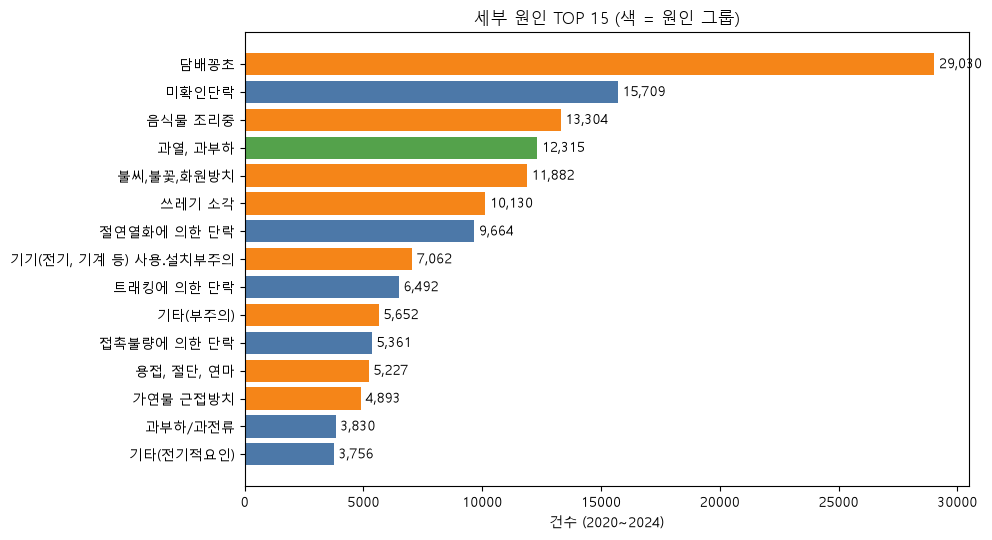

담배꽁초 비중: 전체 화재의 15.2%


In [9]:
top_detail = known['cause_detail'].value_counts().head(15)
group_of = known.drop_duplicates('cause_detail').set_index('cause_detail')['cause_group']

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top_detail.index, top_detail.values, color=[COLORS[group_of[d]] for d in top_detail.index])
ax.invert_yaxis()
ax.set_xlabel('건수 (2020~2024)')
ax.set_title('세부 원인 TOP 15 (색 = 원인 그룹)')
for i, v in enumerate(top_detail.values):
    ax.text(v + 200, i, f'{v:,}', va='center')
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '04_세부원인_TOP15.png'), dpi=200, bbox_inches='tight')
plt.show()

print(f'담배꽁초 비중: 전체 화재의 {(df["cause_detail"] == "담배꽁초").mean():.1%}')

**관찰:** **담배꽁초가 29,030건으로 1위이며, 전체 화재의 15.2%**를 차지합니다. 그 다음은 미확인단락(전기), 음식물 조리중, 과열·과부하(기계), 불씨·불꽃 방치, 쓰레기 소각 순입니다.
상위권 대부분이 **사람의 작은 부주의**로 생기는 화재라서 예방 홍보로 줄일 수 있는 여지가 큽니다.

### 2-6. 어떤 원인의 화재가 더 위험할까? (인명·재산 피해)

                건수  인명피해_발생률  사망자  재산피해_중앙값_만원  재산피해_평균_만원
cause_group                                               
부주의          90849       4.0  355         21.6       707.6
전기적 요인       49759       2.7  233        100.9      2706.2
기계적 요인       19694       2.2   17        132.0      1231.4
기타           14700      11.0  469        115.5      3292.0


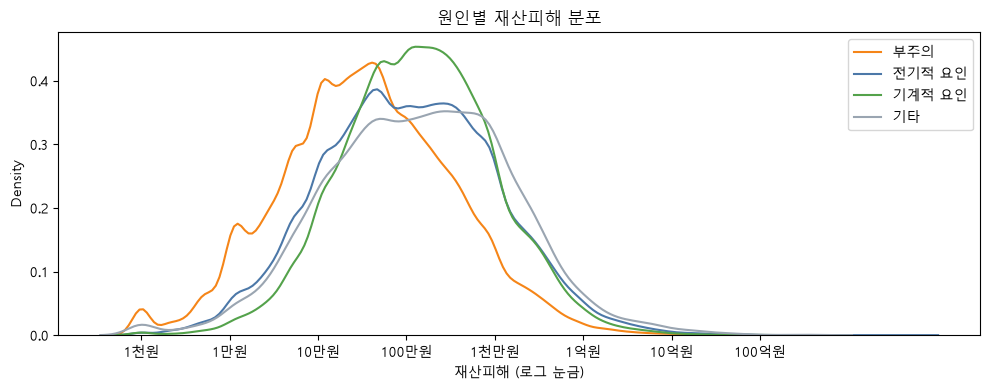

In [10]:
harm = known.groupby('cause_group').agg(
    건수=('casualties', 'size'),
    인명피해_발생률=('casualties', lambda s: (s > 0).mean() * 100),
    사망자=('deaths', 'sum'),
    재산피해_중앙값_만원=('damage', lambda s: s.median() / 10),
    재산피해_평균_만원=('damage', lambda s: s.mean() / 10),
).loc[CLASSES]
print(harm.round(1).to_string())

# 재산피해는 0원부터 수천억 원까지 퍼져 있어 로그 눈금으로 비교
fig, ax = plt.subplots(figsize=(10, 4))
for c in CLASSES:
    d = known.loc[(known['cause_group'] == c) & (known['damage'] > 0), 'damage'] * 1000
    sns.kdeplot(np.log10(d), ax=ax, color=COLORS[c], label=c)
ax.set_xticks(range(3, 11))
ax.set_xticklabels(['1천원', '1만원', '10만원', '100만원', '1천만원', '1억원', '10억원', '100억원'])
ax.set_xlabel('재산피해 (로그 눈금)')
ax.set_title('원인별 재산피해 분포')
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '05_원인별_재산피해분포.png'), dpi=200, bbox_inches='tight')
plt.show()

**관찰:** 건수는 부주의가 가장 많지만 **피해 정도는 원인마다 다릅니다.**
- **기타**(방화·가스누출·교통사고 등)는 인명피해 발생률이 11.0%로 가장 높고, 사망자도 469명으로 가장 많습니다.
- **전기적 요인**은 재산피해 중앙값이 100.9만원으로 **부주의(21.6만원)의 약 4.7배**입니다. 건물 안에서 늦게 발견되는 경우가 많기 때문으로 보입니다.
- 부주의 화재는 건수가 많은 대신 쓰레기·야외 화재처럼 피해가 작은 경우가 많습니다.

## 3. 전처리

In [11]:
# 1) 입력 변수의 원재료: 발생 시점(월·시간·요일)과 장소·지역·화재 유형
#    - 세부 원인(cause_detail)과 피해 규모는 조사가 끝난 뒤에 알 수 있는 정보라 입력에서 제외 (정답 누설 방지)
known['weekday'] = known['datetime'].dt.day_of_week   # 0 = 월요일
known['year'] = known['datetime'].dt.year

# 2) 장소 소분류는 364종이라, 학습 기간(2020~2023)에 30건 미만인 드문 장소는 '기타(드문 장소)'로 묶음
place3_counts = known.loc[known['year'] < 2024, 'place_3'].value_counts()
KEEP_PLACE3 = sorted(place3_counts[place3_counts >= 30].index)
print(f'장소 소분류 {known["place_3"].nunique()}종 중 {len(KEEP_PLACE3)}종 유지, 나머지는 기타로 묶음')

def prepare(d):
    out = d[['month', 'hour', 'weekday', 'sido', 'fire_type', 'place_1', 'place_2']].copy()
    out['place_3'] = d['place_3'].where(d['place_3'].isin(KEEP_PLACE3), '기타(드문 장소)')
    return out

# 3) 모든 입력을 원-핫 인코딩 (월·시간·요일도 '숫자 크기'가 아니라 '구분'으로 다룸)
#    범주 목록을 고정해 두어야 앱에서 한 건만 넣어도 같은 컬럼이 만들어짐
raw_inputs = prepare(known)
CATEGORIES = {col: sorted(raw_inputs[col].unique()) for col in raw_inputs.columns}

def encode(d):
    parts = [pd.get_dummies(pd.Categorical(d[col], categories=cats), prefix=col, dtype=int).set_axis(d.index)
             for col, cats in CATEGORIES.items()]
    return pd.concat(parts, axis=1)

X_all = encode(raw_inputs)
y_all = known['cause_group'].map({c: i for i, c in enumerate(CLASSES)})
print('입력 컬럼 수:', X_all.shape[1])
print('예측 대상:', dict(enumerate(CLASSES)))

장소 소분류 362종 중 189종 유지, 나머지는 기타로 묶음


입력 컬럼 수: 321
예측 대상: {0: '부주의', 1: '전기적 요인', 2: '기계적 요인', 3: '기타'}


## 4. 모델링

### 4-1. 학습/테스트 분할: 시간 순서대로 (2020~2023 학습 → 2024 테스트)
무작위로 나누면 같은 시기의 화재가 학습·테스트에 섞여 **미래를 미리 본** 셈이 됩니다.
실제로는 과거 기록으로 앞으로의 화재를 예측해야 하므로, **2020~2023년으로 학습하고 2024년으로 평가**합니다.

In [12]:
train_mask = (known['year'] < 2024).values
X_train, X_test = X_all[train_mask], X_all[~train_mask]
y_train, y_test = y_all[train_mask], y_all[~train_mask]
print(f'학습(2020~2023): {len(X_train):,}건 / 테스트(2024): {len(X_test):,}건')
print('테스트 데이터 원인 비율:')
print(y_test.map(dict(enumerate(CLASSES))).value_counts(normalize=True).round(3).to_string())

학습(2020~2023): 140,441건 / 테스트(2024): 34,561건


테스트 데이터 원인 비율:
cause_group
부주의       0.490
전기적 요인    0.306
기계적 요인    0.111
기타        0.093


### 4-2. 평가 지표
- **정확도**: 원인을 정확히 맞힌 비율. 단, '부주의'가 절반이라 **모두 부주의라고 찍어도 약 49%**가 나옵니다.
- **매크로 F1**: 4개 원인 각각의 F1을 똑같은 비중으로 평균 → 건수가 적은 원인도 잘 맞히는지 봄
- **상위 2개 적중률**: 모델이 가장 가능성 높다고 본 원인 2개 안에 정답이 있는 비율 → '우선 점검할 방향'으로 쓸 때의 쓸모

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, classification_report, confusion_matrix

def evaluate(name, y_true, proba):
    pred = proba.argmax(axis=1)
    return {'모델': name,
            '정확도': accuracy_score(y_true, pred),
            '매크로 F1': f1_score(y_true, pred, average='macro'),
            '상위 2개 적중률': top_k_accuracy_score(y_true, proba, k=2, labels=range(len(CLASSES)))}

### 4-3. 모델 4개 학습: 최빈값 찍기(기준), 로지스틱 회귀, 랜덤포레스트, XGBoost

In [14]:
candidates = [
    ('0 최빈값 찍기 (기준)', 'dummy', DummyClassifier(strategy='prior')),
    ('① 로지스틱 회귀', 'lr', LogisticRegression(max_iter=1000)),
    ('② 랜덤포레스트', 'rf', RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                  random_state=RANDOM_STATE, n_jobs=-1)),
    ('③ XGBoost', 'xgb', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method='hist',
                                       random_state=RANDOM_STATE, n_jobs=-1)),
]
models, proba, rows, train_rows = {}, {}, [], []
for name, key, m in candidates:
    m.fit(X_train, y_train)
    models[key] = m
    proba[key] = m.predict_proba(X_test)
    rows.append(evaluate(name, y_test, proba[key]))
    train_rows.append(evaluate(name, y_train, m.predict_proba(X_train)))
result_df = pd.DataFrame(rows).set_index('모델')
train_df = pd.DataFrame(train_rows).set_index('모델')
result_df['학습 정확도'] = train_df['정확도']
result_df.round(4)

,정확도,매크로 F1,상위 2개 적중률,학습 정확도
모델,,,,
0 최빈값 찍기 (기준),0.4896,0.1643,0.7960,0.5264
① 로지스틱 회귀,0.5761,0.4223,0.8400,0.6002
② 랜덤포레스트,0.5757,0.4162,0.8418,0.6360
③ XGBoost,0.5782,0.4243,0.8425,0.6196


**관찰:** 학습한 세 모델의 성능은 거의 같습니다(정확도 0.576~0.578, 매크로 F1 0.416~0.424). 최빈값 찍기와 비교하면 다음과 같습니다.
- **정확도:** 0.490 → 0.578 (**+8.9%p**)
- **매크로 F1:** 0.164 → 0.424
- **상위 2개 적중률:** 0.796 → 0.843 (부주의·전기 두 개만 말해도 79.6%라 차이가 크지 않음)
학습 정확도(0.60~0.64)와 테스트 정확도의 차이가 작아 과적합은 거의 없습니다.
**장소·시간 정보만으로는 원인을 절반 남짓 맞히는 수준**이며, 같은 장소·시간이라도 원인이 다양하다는 화재의 특성상 한계가 분명합니다.

최종 모델: ③ XGBoost


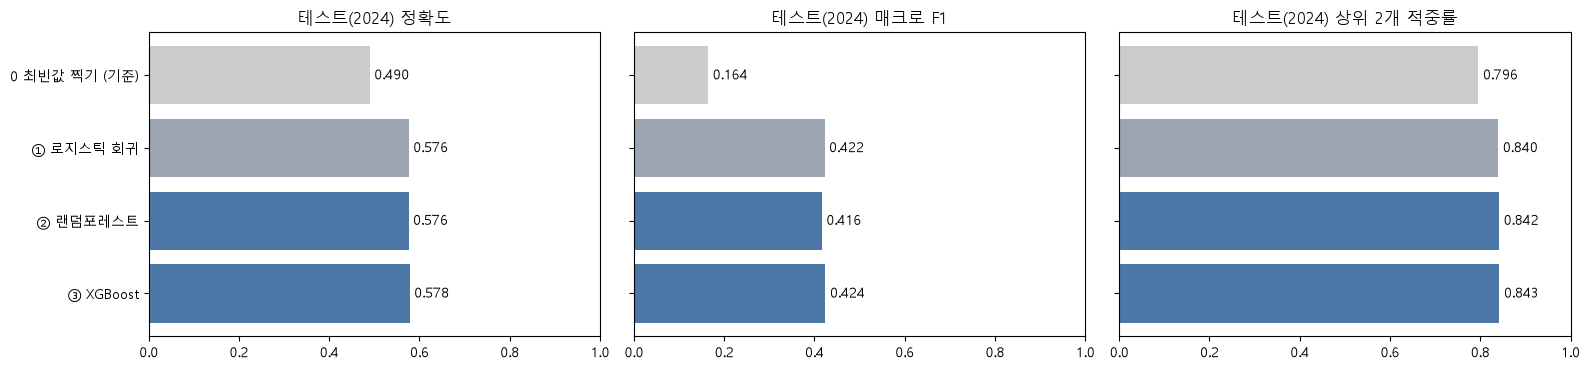

In [15]:
# 테스트 매크로 F1이 가장 높은 모델을 최종 모델로 선택 (정확도는 '부주의'만 잘 맞혀도 높게 나오므로)
key_of = {name: key for name, key, _ in candidates}
best_name = result_df['매크로 F1'].idxmax()
best_key = key_of[best_name]
best_model, proba_best = models[best_key], proba[best_key]
print('최종 모델:', best_name)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
colors = ['#cccccc', '#9aa5b1', '#4c78a8', '#4c78a8']
for ax, col in zip(axes, ['정확도', '매크로 F1', '상위 2개 적중률']):
    ax.barh(result_df.index, result_df[col], color=colors)
    for i, v in enumerate(result_df[col]):
        ax.text(v + 0.01, i, f'{v:.3f}', va='center')
    ax.set_xlim(0, 1)
    ax.set_title(f'테스트(2024) {col}')
axes[0].invert_yaxis()
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '06_모델별_성능비교.png'), dpi=200, bbox_inches='tight')
plt.show()

### 4-4. 원인별로 얼마나 맞히나? (최종 모델)

              precision    recall  f1-score   support

         부주의      0.619     0.849     0.716     16922
      전기적 요인      0.520     0.371     0.433     10587
      기계적 요인      0.439     0.368     0.400      3823
          기타      0.469     0.088     0.148      3229

    accuracy                          0.578     34561
   macro avg      0.512     0.419     0.424     34561
weighted avg      0.555     0.578     0.541     34561



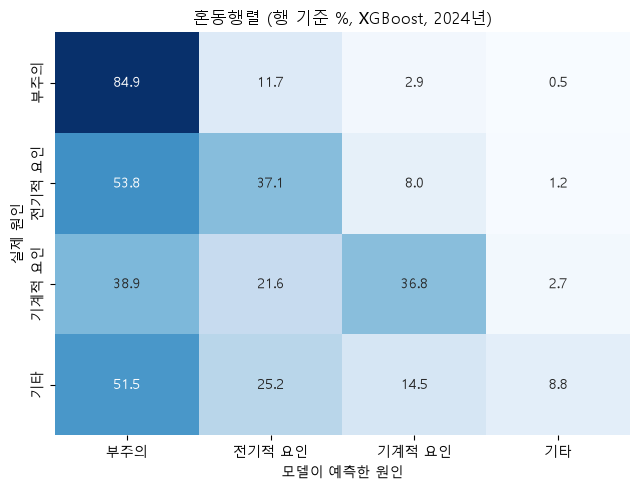

In [16]:
pred_best = proba_best.argmax(axis=1)
print(classification_report(y_test, pred_best, target_names=CLASSES, digits=3))

# 혼동행렬: 실제 원인별로 모델이 무엇이라고 답했는지 (행 기준 비율)
cm = confusion_matrix(y_test, pred_best, normalize='true') * 100
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=ax, xticklabels=CLASSES, yticklabels=CLASSES)
ax.set_xlabel('모델이 예측한 원인')
ax.set_ylabel('실제 원인')
ax.set_title(f'혼동행렬 (행 기준 %, {best_name[2:]}, 2024년)')
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '07_혼동행렬.png'), dpi=200, bbox_inches='tight')
plt.show()

**관찰:** 원인별 재현율(실제 그 원인인 화재 중 맞힌 비율)은 **부주의 84.9%, 전기적 요인 37.1%, 기계적 요인 36.8%, 기타 8.8%**입니다.
모델은 확실하지 않으면 가장 흔한 '부주의'로 답하는 경향이 있습니다. '기타'는 방화·가스·교통사고 등 성격이 다른 원인을 묶은 그룹이라 공통된 패턴이 약해서 거의 맞히지 못합니다.

### 4-5. 연도를 바꿔 가며 검증 (시간 순서 교차검증)
2024년 한 해만 보면 우연일 수 있으므로, **"그 전 해까지로 학습 → 다음 해 예측"**을 2022·2023·2024년에 반복합니다.

In [17]:
from sklearn.base import clone

years = known['year'].values
cv_rows = []
for test_year in [2022, 2023, 2024]:
    tr, te = years < test_year, years == test_year
    for name, key, m in candidates:
        mm = clone(m).fit(X_all[tr], y_all[tr])
        r = evaluate(name, y_all[te], mm.predict_proba(X_all[te]))
        r['테스트 연도'] = test_year
        cv_rows.append(r)
cv_df = pd.DataFrame(cv_rows).pivot_table(index='모델', columns='테스트 연도', values=['정확도', '매크로 F1'])
cv_df.round(3)

매크로 F1                  정확도              
테스트 연도          2022   2023   2024   2022   2023   2024
모델                                                     
0 최빈값 찍기 (기준)  0.175  0.170  0.164  0.540  0.514  0.490
① 로지스틱 회귀      0.414  0.424  0.422  0.601  0.595  0.576
② 랜덤포레스트       0.406  0.418  0.416  0.601  0.593  0.576
③ XGBoost      0.417  0.424  0.424  0.603  0.595  0.578

**관찰:** 세 해 모두 같은 순서와 비슷한 수준이 나와 **결과가 특정 연도의 우연이 아닙니다.** XGBoost의 매크로 F1은 0.417 / 0.424 / 0.424로 안정적입니다.
흥미롭게도 부주의 비율이 해마다 줄어서(최빈값 정확도 0.540 → 0.514 → 0.490) 찍기 기준은 낮아지는데, **모델과 찍기의 정확도 차이는 6.3%p → 8.1%p → 8.8%p로 커집니다.**

### 4-6. 모델 저장 (joblib)

In [18]:
import joblib

os.makedirs('model', exist_ok=True)
MODEL_PATH = os.path.join('model', 'fire_cause_model.pkl')
# 앱에서 같은 인코딩을 하도록 범주 목록·장소 목록·원인 이름을 모델과 함께 저장
joblib.dump({'model': best_model, 'classes': CLASSES, 'categories': CATEGORIES,
             'keep_place3': KEEP_PLACE3, 'columns': list(X_all.columns)}, MODEL_PATH)

loaded = joblib.load(MODEL_PATH)
same = np.allclose(loaded['model'].predict_proba(X_test), proba_best)
print('저장 모델:', best_name)
print('저장 파일:', MODEL_PATH, f'({os.path.getsize(MODEL_PATH) / 1024 / 1024:.1f} MB)')
print('불러온 모델의 예측이 같은가:', same)

저장 모델: ③ XGBoost
저장 파일: model\fire_cause_model.pkl (3.5 MB)
불러온 모델의 예측이 같은가: True


## 5. 해석

### 5-1. 무엇이 원인 예측에 중요할까? (순열 중요도)
2024년 테스트 데이터에서 **원래 변수 하나를 뒤섞은 뒤** 다시 인코딩해 예측했을 때 매크로 F1이 얼마나 떨어지는지 봅니다.
장소 대·중·소분류는 서로 얽혀 있어 '장소' 하나로 묶어서 섞습니다.

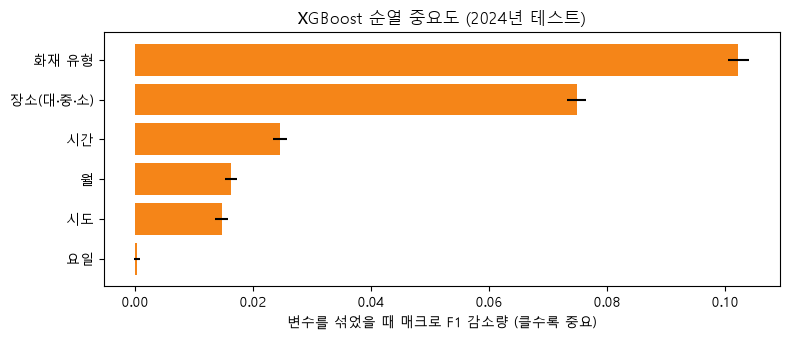

           평균 F1 감소    표준편차
화재 유형        0.1023  0.0018
장소(대·중·소)    0.0749  0.0016
시간           0.0246  0.0012
월            0.0163  0.0010
시도           0.0147  0.0011
요일           0.0004  0.0005


In [19]:
rng = np.random.default_rng(RANDOM_STATE)
test_raw = raw_inputs[~train_mask]
base_f1 = f1_score(y_test, pred_best, average='macro')
groups = {'장소(대·중·소)': ['place_1', 'place_2', 'place_3'], '화재 유형': ['fire_type'], '월': ['month'],
          '시간': ['hour'], '요일': ['weekday'], '시도': ['sido']}
perm_rows = {}
for gname, cols in groups.items():
    drops = []
    for _ in range(5):   # 5번 반복해 평균 (우연한 결과를 줄이기 위해)
        shuffled = test_raw.copy()
        shuffled[cols] = shuffled[cols].values[rng.permutation(len(shuffled))]
        drops.append(base_f1 - f1_score(y_test, best_model.predict(encode(shuffled)), average='macro'))
    perm_rows[gname] = {'평균 F1 감소': np.mean(drops), '표준편차': np.std(drops)}
perm_df = pd.DataFrame(perm_rows).T.sort_values('평균 F1 감소')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(perm_df.index, perm_df['평균 F1 감소'], xerr=perm_df['표준편차'], color='#f58518')
ax.set_title(f'{best_name[2:]} 순열 중요도 (2024년 테스트)')
ax.set_xlabel('변수를 섞었을 때 매크로 F1 감소량 (클수록 중요)')
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '08_순열중요도.png'), dpi=200, bbox_inches='tight')
plt.show()

print(perm_df.sort_values('평균 F1 감소', ascending=False).round(4).to_string())

**관찰:** **화재 유형(0.102)과 장소(0.075)가 압도적으로 중요**하고, 그 다음이 시간(0.025)·월(0.016)·시도(0.015)입니다. 요일은 거의 영향이 없습니다(0.0004).
'무엇이 어디서 탔는가'가 원인을 가장 잘 알려 주고, '언제'는 보조 정보 역할을 합니다.

### 5-2. 원인 '미상' 화재의 원인 추정
원인을 끝내 밝히지 못한 화재에 모델을 적용해, 어떤 원인이었을 가능성이 높은지 추정합니다.

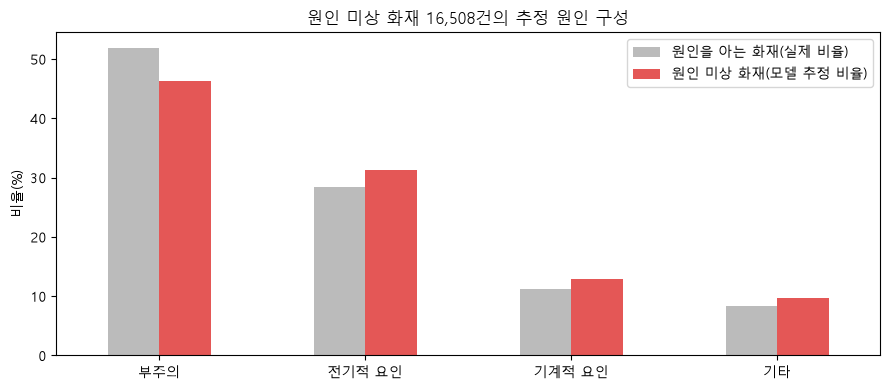

        원인을 아는 화재(실제 비율)  원인 미상 화재(모델 추정 비율)
부주의                 51.9           46.299999
전기적 요인              28.4           31.200001
기계적 요인              11.3           12.900000
기타                   8.4            9.700000

원인 미상 화재의 화재 유형 구성 vs 전체:
                미상  원인 아는 화재
fire_type                   
건축,구조물       0.719     0.640
기타(쓰레기 화재등)  0.085     0.200
선박,항공기       0.006     0.003
위험물,가스제조소등   0.001     0.001
임야           0.035     0.038
자동차,철도차량     0.154     0.119


In [20]:
unknown = df[df['cause_group'] == '미상'].copy()
unknown['month'] = unknown['datetime'].dt.month
unknown['hour'] = unknown['datetime'].dt.hour
unknown['weekday'] = unknown['datetime'].dt.day_of_week
unk_proba = best_model.predict_proba(encode(prepare(unknown)))

# 확률의 평균 = 미상 화재 전체에서 각 원인이 차지할 것으로 추정되는 비율
compare = pd.DataFrame({
    '원인을 아는 화재(실제 비율)': known['cause_group'].value_counts(normalize=True).reindex(CLASSES) * 100,
    '원인 미상 화재(모델 추정 비율)': pd.Series(unk_proba.mean(axis=0) * 100, index=CLASSES),
})
ax = compare.plot.bar(figsize=(9, 4), color=['#bbbbbb', '#e45756'], rot=0)
ax.set_ylabel('비율(%)')
ax.set_title(f'원인 미상 화재 {len(unknown):,}건의 추정 원인 구성')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '09_원인미상_화재_추정.png'), dpi=200, bbox_inches='tight')
plt.show()

print(compare.round(1).to_string())
print()
print('원인 미상 화재의 화재 유형 구성 vs 전체:')
print(pd.DataFrame({'미상': unknown['fire_type'].value_counts(normalize=True),
                    '원인 아는 화재': known['fire_type'].value_counts(normalize=True)}).round(3).to_string())

**관찰:** 원인 미상 화재 16,508건에 모델을 적용하면 **부주의 46.3%, 전기적 요인 31.2%, 기계적 요인 12.9%, 기타 9.7%**로 추정됩니다. 원인을 아는 화재보다 **부주의는 적고 전기·기계적 요인은 많습니다.**
미상 화재는 건물(71.9% vs 64.0%)과 자동차(15.4% vs 11.9%) 화재가 많고 쓰레기 화재(8.5% vs 20.0%)가 적기 때문입니다. 불에 타 증거가 사라지기 쉬운 **건물·차량 화재일수록 원인을 밝히기 어렵다**는 해석이 가능합니다.
(단, '미상 화재도 원인을 아는 화재와 비슷한 패턴을 따른다'는 가정 위의 추정입니다.)

### 5-3. 상황별 예측 예시

In [21]:
def scenario(month, hour, weekday, sido, fire_type, place_1, place_2, place_3):
    row = pd.DataFrame([{'month': month, 'hour': hour, 'weekday': weekday, 'sido': sido, 'fire_type': fire_type,
                         'place_1': place_1, 'place_2': place_2, 'place_3': place_3}])
    return pd.Series(best_model.predict_proba(encode(prepare(row)))[0] * 100, index=CLASSES).round(1)

examples = {
    '1월 저녁 7시, 서울 치킨·족발집': (1, 19, 4, '서울특별시', '건축,구조물', '생활서비스', '음식점', '치킨,족발'),
    '8월 오후 3시, 경기 아파트': (8, 15, 2, '경기도', '건축,구조물', '주거', '공동주택', '아파트'),
    '4월 오후 2시, 경북 논밭두렁': (4, 14, 5, '경상북도', '임야', '임야', '들불', '논밭두렁'),
    '7월 오후 1시, 경기 승용차': (7, 13, 1, '경기도', '자동차,철도차량', '자동차,철도차량', '자동차', '승용자동차'),
}
pd.DataFrame({k: scenario(*v) for k, v in examples.items()}).T

,부주의,전기적 요인,기계적 요인,기타
"1월 저녁 7시, 서울 치킨·족발집",54.099998,19.000000,13.400000,13.500000
"8월 오후 3시, 경기 아파트",31.299999,53.500000,8.500000,6.700000
"4월 오후 2시, 경북 논밭두렁",96.900002,1.200000,0.600000,1.300000
"7월 오후 1시, 경기 승용차",11.300000,32.700001,37.299999,18.700001


**관찰:** - **1월 저녁 7시 치킨집:** 부주의 54.1% (조리 중 부주의)
- **8월 오후 3시 아파트:** 전기적 요인 53.5%로 1위 (여름철 전기 사용)
- **4월 오후 2시 논밭두렁:** 부주의 96.9% (논밭 태우기)
- **7월 오후 1시 승용차:** 기계적 요인 37.3%, 전기적 요인 32.7%로 비슷
같은 화재 유형이라도 장소와 계절에 따라 우선 의심할 원인이 달라집니다.

## 6. 모델 최적화와 활용 분석

### 6-1. 원인 그룹 분포와 변수 간 연관성
예측 대상(원인 그룹)의 비율과, 범주형 변수끼리 얼마나 관련 있는지(**크래머 V**: 0 = 무관, 1 = 완전히 관련)를 확인합니다.
이 데이터의 입력 변수는 모두 범주형이라 일반 상관계수 대신 크래머 V를 씁니다.

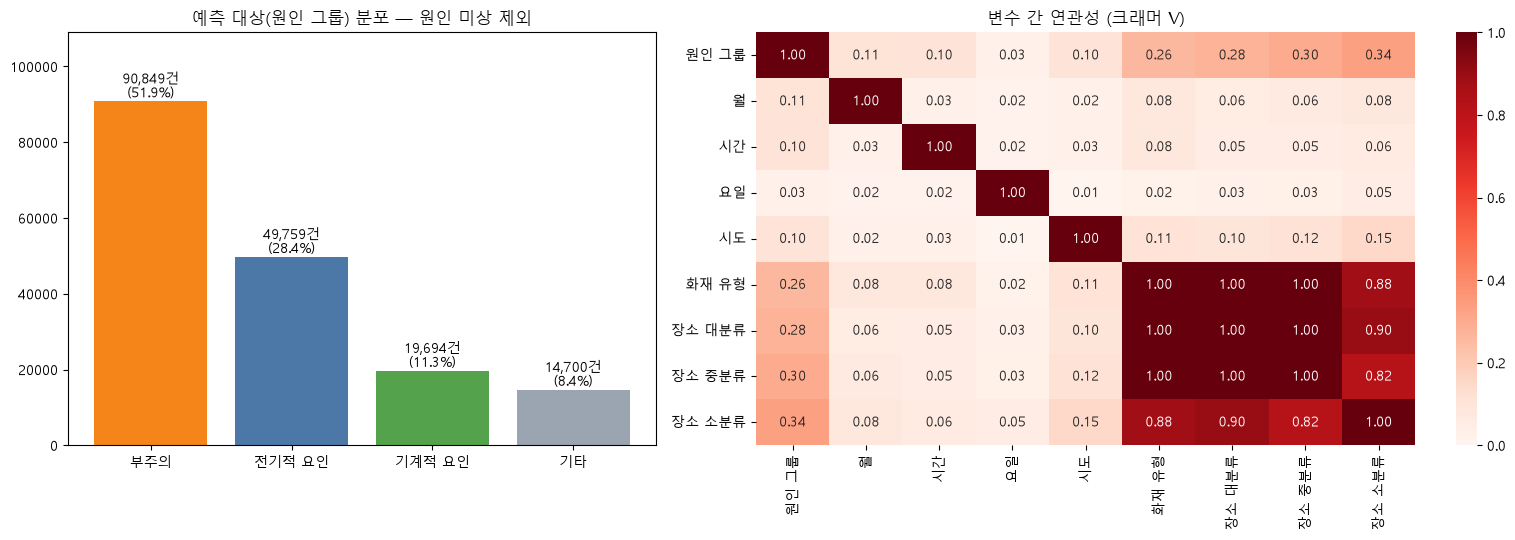

원인 그룹과의 연관성(크래머 V):
장소 소분류    0.336
장소 중분류    0.300
장소 대분류    0.277
화재 유형     0.261
월         0.106
시간        0.103
시도        0.103
요일        0.025


In [22]:
from scipy.stats import chi2_contingency

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1, 1.4]})
share = known['cause_group'].value_counts().reindex(CLASSES)
axes[0].bar(share.index, share.values, color=[COLORS[c] for c in CLASSES])
for i, v in enumerate(share.values):
    axes[0].text(i, v + 1000, f'{v:,}건\n({v / share.sum():.1%})', ha='center')
axes[0].set_title('예측 대상(원인 그룹) 분포 — 원인 미상 제외')
axes[0].set_ylim(0, share.max() * 1.2)

def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

cv_cols = {'원인 그룹': known['cause_group'], '월': known['month'], '시간': known['hour'], '요일': known['weekday'],
           '시도': known['sido'], '화재 유형': known['fire_type'], '장소 대분류': known['place_1'],
           '장소 중분류': known['place_2'], '장소 소분류': raw_inputs['place_3']}
names_cv = list(cv_cols)
cv_mat = pd.DataFrame([[cramers_v(cv_cols[a], cv_cols[b]) for b in names_cv] for a in names_cv], index=names_cv, columns=names_cv)
sns.heatmap(cv_mat, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('변수 간 연관성 (크래머 V)')
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '11_원인분포_변수연관성.png'), dpi=200, bbox_inches='tight')
plt.show()

print('원인 그룹과의 연관성(크래머 V):')
print(cv_mat['원인 그룹'].drop('원인 그룹').sort_values(ascending=False).round(3).to_string())

**관찰:** 원인을 아는 화재 175,002건 중 **부주의 51.9%, 전기적 요인 28.4%, 기계적 요인 11.3%, 기타 8.4%**로 불균형합니다.
원인 그룹과의 연관성은 **장소 소분류(0.336) > 장소 중분류(0.300) > 장소 대분류(0.277) > 화재 유형(0.261)** 순으로 높고, 월·시간·시도는 약 0.10, 요일은 0.025로 거의 무관합니다. 5-1의 순열 중요도와 같은 결론입니다.
장소 대·중·소분류와 화재 유형은 서로 연관성이 매우 높아(같은 정보를 단계별로 나눈 것), 트리 모델처럼 변수 간 중복에 강한 모델이 적합합니다.

### 6-2. 모델별 상세 성능 (매크로 평균)과 과적합 확인

테스트(2024) 매크로 평균 성능
               Accuracy  Precision  Recall  F1 Score  ROC-AUC
0 최빈값 찍기 (기준)     0.490      0.122   0.250     0.164    0.500
① 로지스틱 회귀         0.576      0.508   0.415     0.422    0.746
② 랜덤포레스트          0.576      0.509   0.412     0.416    0.747
③ XGBoost         0.578      0.512   0.419     0.424    0.748



           학습 정확도  테스트 정확도  학습 매크로 F1  테스트 매크로 F1  정확도 차이
모델                                                       
① 로지스틱 회귀   0.600    0.576      0.424       0.422   0.024
② 랜덤포레스트    0.636    0.576      0.465       0.416   0.060
③ XGBoost   0.620    0.578      0.450       0.424   0.041


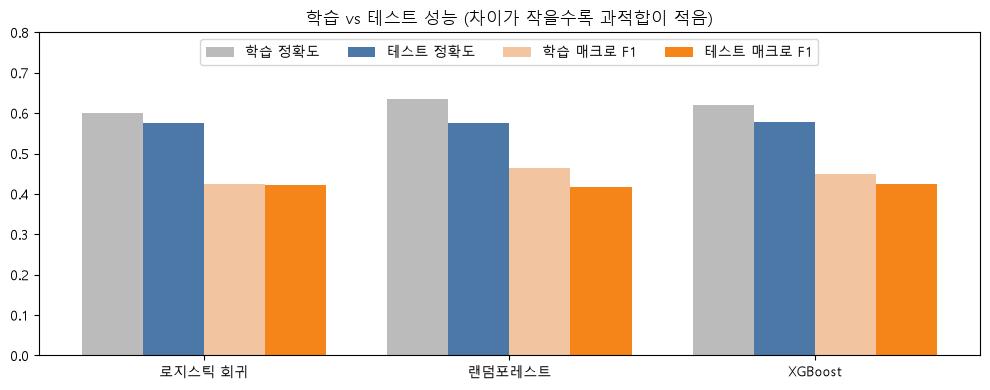

In [23]:
from sklearn.metrics import precision_score, recall_score, roc_auc_score

def detail_scores(y_true, proba_):
    pred = proba_.argmax(axis=1)
    return {'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred, average='macro', zero_division=0),
            'Recall': recall_score(y_true, pred, average='macro'),
            'F1 Score': f1_score(y_true, pred, average='macro'),
            'ROC-AUC': roc_auc_score(y_true, proba_, multi_class='ovr', average='macro')}

detail_df = pd.DataFrame({name: detail_scores(y_test, proba[key]) for name, key, _ in candidates}).T
print('테스트(2024) 매크로 평균 성능')
print(detail_df.round(3).to_string())

# 과적합 확인: 학습 데이터 성능과 테스트 성능 비교
fit_df = pd.DataFrame({
    '학습 정확도': train_df['정확도'], '테스트 정확도': result_df['정확도'],
    '학습 매크로 F1': train_df['매크로 F1'], '테스트 매크로 F1': result_df['매크로 F1'],
}).drop(index=[n for n, k, _ in candidates if k == 'dummy'])
fit_df['정확도 차이'] = fit_df['학습 정확도'] - fit_df['테스트 정확도']
print()
print(fit_df.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(fit_df))
for i, (col, color) in enumerate([('학습 정확도', '#bbbbbb'), ('테스트 정확도', '#4c78a8'),
                                  ('학습 매크로 F1', '#f2c4a0'), ('테스트 매크로 F1', '#f58518')]):
    ax.bar(x + (i - 1.5) * 0.2, fit_df[col], width=0.2, color=color, label=col)
ax.set_xticks(x)
ax.set_xticklabels([n[2:] for n in fit_df.index])
ax.set_ylim(0, 0.8)
ax.set_title('학습 vs 테스트 성능 (차이가 작을수록 과적합이 적음)')
ax.legend(ncol=4, loc='upper center')
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '12_과적합확인.png'), dpi=200, bbox_inches='tight')
plt.show()

**관찰:** **담배꽁초가 29,030건으로 1위이며, 전체 화재의 15.2%**를 차지합니다. 그 다음은 미확인단락(전기), 음식물 조리중, 과열·과부하(기계), 불씨·불꽃 방치, 쓰레기 소각 순입니다.
상위권 대부분이 **사람의 작은 부주의**로 생기는 화재라서 예방 홍보로 줄일 수 있는 여지가 큽니다._SCORE

### 6-3. 하이퍼파라미터 탐색 (XGBoost)
테스트(2024) 데이터는 끝까지 보지 않고, **2020~2022년으로 학습 → 2023년으로 검증**하는 시간 순서 검증으로 설정을 고릅니다.
평가 기준은 **매크로 ROC-AUC**(4개 원인 각각을 얼마나 잘 구분하는지의 평균)입니다.
- 1차: 넓은 범위에서 무작위로 10개 조합 탐색
- 2차: 1차 최적값 주변을 좁혀서 격자 탐색

In [24]:
import time
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, PredefinedSplit

# 검증 설정: 2020~2022 학습(-1) / 2023 검증(0) — 2024년은 사용하지 않음
search_mask = years < 2024
X_search, y_search = X_all[search_mask], y_all[search_mask]
split = PredefinedSplit(np.where(years[search_mask] == 2023, 0, -1))
base_xgb = XGBClassifier(tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1)

space1 = {'n_estimators': [200, 400, 600], 'max_depth': [4, 6, 8, 10], 'learning_rate': [0.03, 0.05, 0.1, 0.2],
          'min_child_weight': [1, 5, 10], 'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.5, 0.7, 1.0]}
t0 = time.time()
search1 = RandomizedSearchCV(base_xgb, space1, n_iter=10, scoring='roc_auc_ovr', cv=split, refit=False,
                             random_state=RANDOM_STATE)
search1.fit(X_search, y_search)
time1 = time.time() - t0
best1 = search1.best_params_
print(f'1차 탐색 ({time1 / 60:.1f}분) 최고 검증 ROC-AUC: {search1.best_score_:.4f}')
print(best1)
pd.DataFrame(search1.cv_results_)[['params', 'mean_test_score']].sort_values('mean_test_score', ascending=False).head(5)

1차 탐색 (6.3분) 최고 검증 ROC-AUC: 0.7551
{'subsample': 0.7, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


,params,mean_test_score
4,"{'subsample': 0.7, 'n_estimators': 600, 'min_c...",0.755071
0,"{'subsample': 0.85, 'n_estimators': 200, 'min_...",0.754746
3,"{'subsample': 1.0, 'n_estimators': 400, 'min_c...",0.753831
7,"{'subsample': 0.85, 'n_estimators': 600, 'min_...",0.753796
5,"{'subsample': 0.7, 'n_estimators': 200, 'min_c...",0.753236


In [25]:
# 2차: 1차에서 고른 깊이·학습률 주변을 좁혀서 격자 탐색 (나머지는 1차 최적값으로 고정)
space2 = {
    'max_depth': sorted({max(3, best1['max_depth'] - 2), best1['max_depth'], best1['max_depth'] + 2}),
    'learning_rate': sorted({round(best1['learning_rate'] / 2, 3), best1['learning_rate']}),
}
fixed2 = {k: v for k, v in best1.items() if k not in space2}
t0 = time.time()
search2 = GridSearchCV(clone(base_xgb).set_params(**fixed2), space2, scoring='roc_auc_ovr', cv=split, refit=False)
search2.fit(X_search, y_search)
time2 = time.time() - t0
best2 = {**fixed2, **search2.best_params_}
print(f'2차 탐색 ({time2 / 60:.1f}분) 최고 검증 ROC-AUC: {search2.best_score_:.4f}')
print(best2)
pd.DataFrame(search2.cv_results_)[['params', 'mean_test_score']].sort_values('mean_test_score', ascending=False)

2차 탐색 (4.6분) 최고 검증 ROC-AUC: 0.7552
{'subsample': 0.7, 'n_estimators': 600, 'min_child_weight': 5, 'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 6}


,params,mean_test_score
2,"{'learning_rate': 0.05, 'max_depth': 6}",0.755215
4,"{'learning_rate': 0.1, 'max_depth': 4}",0.755071
3,"{'learning_rate': 0.1, 'max_depth': 3}",0.754725
1,"{'learning_rate': 0.05, 'max_depth': 4}",0.754549
5,"{'learning_rate': 0.1, 'max_depth': 6}",0.753650
0,"{'learning_rate': 0.05, 'max_depth': 3}",0.752689


In [26]:
# 튜닝한 설정으로 2020~2023 전체를 다시 학습해 2024년으로 최종 평가 (기본 설정 XGBoost와 비교)
default_params = {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.1, 'min_child_weight': 1,
                  'subsample': 1.0, 'colsample_bytree': 1.0}
tuned_model = clone(base_xgb).set_params(**best2).fit(X_train, y_train)
proba_tuned = tuned_model.predict_proba(X_test)
compare_tune = pd.DataFrame({'기본 설정': detail_scores(y_test, proba[best_key]),
                             '튜닝 후': detail_scores(y_test, proba_tuned)})
compare_tune['차이'] = compare_tune['튜닝 후'] - compare_tune['기본 설정']
print(pd.DataFrame({'조정 전': default_params, '최종 모델': best2}).to_string())
print()
print(compare_tune.round(4).to_string())

                   조정 전   최종 모델
n_estimators      300.0  600.00
max_depth           6.0    6.00
learning_rate       0.1    0.05
min_child_weight    1.0    5.00
subsample           1.0    0.70
colsample_bytree    1.0    1.00

            기본 설정    튜닝 후      차이
Accuracy   0.5782  0.5808  0.0027
Precision  0.5119  0.5134  0.0015
Recall     0.4188  0.4217  0.0029
F1 Score   0.4243  0.4294  0.0051
ROC-AUC    0.7481  0.7495  0.0013


In [27]:
# 검증(2023) ROC-AUC가 더 높은 쪽을 최종 모델로 사용 (테스트 결과로 고르지 않음)
val_default = roc_auc_score(y_all[years == 2023],
                            clone(base_xgb).set_params(**default_params).fit(X_all[years < 2023], y_all[years < 2023])
                            .predict_proba(X_all[years == 2023]), multi_class='ovr')
print(f'2023 검증 ROC-AUC — 기본 설정: {val_default:.4f} / 튜닝: {search2.best_score_:.4f}')
if search2.best_score_ > val_default:
    final_model, proba_final, final_params = tuned_model, proba_tuned, best2
    print('→ 튜닝한 모델을 최종 모델로 저장')
else:
    final_model, proba_final, final_params = best_model, proba_best, default_params
    print('→ 기본 설정이 더 나아 그대로 유지')
joblib.dump({'model': final_model, 'classes': CLASSES, 'categories': CATEGORIES,
             'keep_place3': KEEP_PLACE3, 'columns': list(X_all.columns)}, MODEL_PATH)
print('저장:', MODEL_PATH)

2023 검증 ROC-AUC — 기본 설정: 0.7523 / 튜닝: 0.7552
→ 튜닝한 모델을 최종 모델로 저장
저장: model\fire_cause_model.pkl


**관찰:** 1차 무작위 탐색(10개 조합, 6.3분)에서 검증 ROC-AUC 0.7551, 2차 격자 탐색(6개 조합, 4.6분)에서 **0.7552**(학습률 0.05, 깊이 6, 나무 600개, min_child_weight 5, subsample 0.7)를 얻었습니다.
2023년 검증 기준 기본 설정(0.7523)보다 높아 **튜닝 모델을 최종 모델로 저장**했습니다. 2024년 테스트에서도 정확도 0.578 → **0.581**, 매크로 F1 0.424 → **0.429**, ROC-AUC 0.748 → **0.750**으로 모든 지표가 조금씩 좋아졌습니다.
다만 개선 폭이 작아(정확도 +0.3%p), **성능을 제한하는 것은 모델 설정보다 입력 정보의 양**이라는 4-3의 판단이 다시 확인됩니다.

### 6-4. 저중요도 변수 제거 검증
5-1에서 중요도가 가장 낮았던 **요일**, 그 다음으로 낮은 **시도**를 빼고 다시 학습해 성능이 유지되는지 확인합니다.

In [28]:
def without(cols):
    keep = [c for c in X_all.columns if not any(c.startswith(p + '_') for p in cols)]
    m = clone(final_model).fit(X_train[keep], y_train)
    return detail_scores(y_test, m.predict_proba(X_test[keep]))

drop_rows = []
for label, cols in [('없음 (8개 전부 사용)', []), ('요일', ['weekday']), ('요일, 시도', ['weekday', 'sido'])]:
    r = without(cols)
    drop_rows.append({'변수 수': 8 - len(cols), '제거 변수': label, 'Accuracy': r['Accuracy'], 'Recall': r['Recall'],
                      'F1': r['F1 Score'], 'ROC-AUC': r['ROC-AUC']})
drop_df = pd.DataFrame(drop_rows)
drop_df.round(4)

,변수 수,제거 변수,Accuracy,Recall,F1,ROC-AUC
0,8,없음 (8개 전부 사용),0.5808,0.4217,0.4294,0.7495
1,7,요일,0.5799,0.4200,0.4274,0.7496
2,6,"요일, 시도",0.5746,0.4151,0.4210,0.7397


**관찰:** **요일을 빼도 성능이 거의 같습니다**(정확도 0.581 → 0.580, ROC-AUC 0.750 → 0.750). 요일은 원인 예측에 거의 쓸모가 없습니다.
시도까지 빼면 정확도 0.575, ROC-AUC 0.740으로 떨어지므로 **시도는 작지만 의미 있는 정보**입니다.
앱 사용자 입장에서 요일 입력은 부담이 작고 성능 차이도 거의 없어, 최종 모델은 8개 변수를 모두 그대로 사용합니다.

### 6-5. 전기화재 위험등급과 예상 손실
전기화재는 부주의 화재보다 재산피해가 크고(2-6), 미리 점검하면 줄일 수 있습니다.
모델이 계산한 **전기적 요인 확률**에 **그 장소에서 전기화재가 났을 때의 피해 금액**(학습 기간 중앙값)을 곱해 **예상 손실**을 구하고,
전기적 요인 확률로 **위험등급**을 나눕니다. 등급 기준은 학습 데이터(2020~2023)의 예측 확률 분포로 정하고, 2024년 데이터로 검증합니다.

In [29]:
e_idx = CLASSES.index('전기적 요인')
train_known = known[train_mask]
# 장소 중분류별 전기화재 재산피해 중앙값 (만원), 건수가 적은 장소는 전체 중앙값으로 대체
elec_train = train_known[train_known['cause_group'] == '전기적 요인']
amount_by_place = elec_train.groupby('place_2')['damage'].agg(['median', 'size'])
overall_amount = elec_train['damage'].median()
amount_map = amount_by_place['median'].where(amount_by_place['size'] >= 30, overall_amount) / 10

p_train = final_model.predict_proba(X_train)[:, e_idx]
q_hi, q_mid = np.quantile(p_train, [0.8, 0.5])   # 상위 20% = 고위험, 그다음 30% = 중위험

test_known = known[~train_mask].copy()
test_known['p_elec'] = proba_final[:, e_idx]
test_known['amount'] = test_known['place_2'].map(amount_map).fillna(overall_amount / 10)
test_known['expected_loss'] = test_known['p_elec'] * test_known['amount']
test_known['grade'] = np.select([test_known['p_elec'] >= q_hi, test_known['p_elec'] >= q_mid], ['고위험', '중위험'], '저위험')

grade_df = test_known.groupby('grade').agg(
    건수=('grade', 'size'),
    실제_전기화재_비율=('cause_group', lambda s: (s == '전기적 요인').mean()),
    평균_예측확률=('p_elec', 'mean'),
    평균_피해금액_만원=('amount', 'mean'),
    평균_예상손실_만원=('expected_loss', 'mean'),
).reindex(['고위험', '중위험', '저위험'])
grade_df['구분 기준'] = [f'전기 확률 ≥ {q_hi:.2f}', f'{q_mid:.2f} ≤ 확률 < {q_hi:.2f}', f'확률 < {q_mid:.2f}']
print(f'2024년 전체 전기화재 비율: {(test_known["cause_group"] == "전기적 요인").mean():.1%}')
grade_df.round(3)

2024년 전체 전기화재 비율: 30.6%


,건수,실제_전기화재_비율,평균_예측확률,평균_피해금액_만원,평균_예상손실_만원,구분 기준
grade,,,,,,
고위험,7307,0.538,0.515,144.242,74.313,전기 확률 ≥ 0.41
중위험,10634,0.357,0.333,143.317,47.791,0.28 ≤ 확률 < 0.41
저위험,16620,0.172,0.155,91.234,18.263,확률 < 0.28


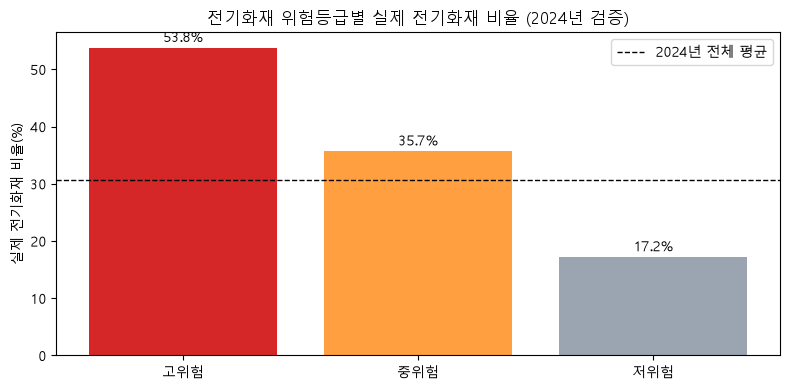

In [30]:
# 등급별 실제 전기화재 비율 그래프
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(grade_df.index, grade_df['실제_전기화재_비율'] * 100, color=['#d62728', '#ff9f40', '#9aa5b1'])
ax.axhline((test_known['cause_group'] == '전기적 요인').mean() * 100, color='black', linestyle='--', linewidth=1, label='2024년 전체 평균')
for i, v in enumerate(grade_df['실제_전기화재_비율'] * 100):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center')
ax.set_ylabel('실제 전기화재 비율(%)')
ax.set_title('전기화재 위험등급별 실제 전기화재 비율 (2024년 검증)')
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '13_전기화재_위험등급.png'), dpi=200, bbox_inches='tight')
plt.show()

**관찰:** 위험등급이 높을수록 실제 전기화재 비율이 뚜렷하게 높습니다. **고위험 53.8% → 중위험 35.7% → 저위험 17.2%**로, 고위험 등급은 2024년 전체 평균(30.6%)의 약 1.8배이고 저위험의 약 3.1배입니다.
각 등급의 평균 예측확률(0.515 / 0.333 / 0.155)이 실제 비율(0.538 / 0.357 / 0.172)과 가까워, **모델이 계산한 확률을 그대로 믿고 써도 될 만큼 잘 맞습니다.**
평균 예상손실은 고위험 74.3만원, 중위험 47.8만원, 저위험 18.3만원으로, 고위험 장소부터 전기 안전 점검을 하면 같은 노력으로 더 큰 피해를 줄일 수 있습니다.

### 6-6. 비교 실험: 클래스 가중치 적용 여부
'부주의'가 절반이라 모델이 부주의 쪽으로 쏠리는 문제(4-4)를 줄이기 위해, **건수가 적은 원인에 더 큰 가중치**를 주고 같은 1차 탐색을 해서 비교합니다.

                 가중치 없음 (1차 탐색 최적)  클래스 균형 가중치      차이
Best CV ROC-AUC             0.7551      0.7361 -0.0190
Accuracy                    0.5802      0.5247 -0.0555
Precision                   0.5108      0.4459 -0.0650
Recall                      0.4211      0.4754  0.0543
F1 Score                    0.4282      0.4530  0.0248
ROC-AUC                     0.7495      0.7400 -0.0095
탐색 시간(분)                    6.2529      6.2419 -0.0111

클래스 가중치 모델의 원인별 재현율:
부주의       0.585
전기적 요인    0.499
기계적 요인    0.520
기타        0.297


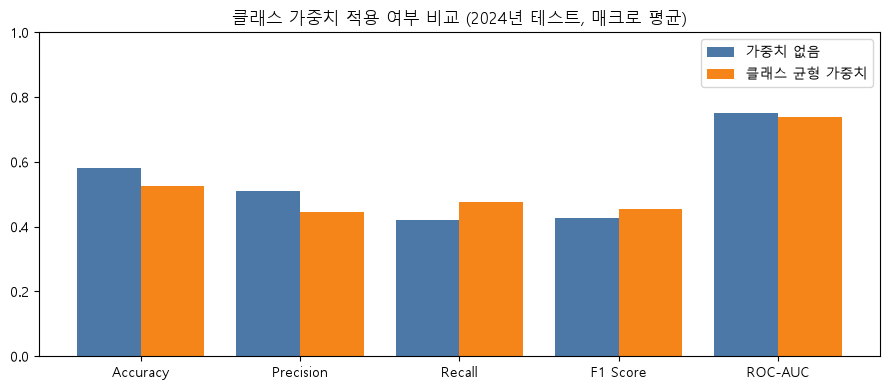

In [31]:
from sklearn.utils.class_weight import compute_sample_weight

t0 = time.time()
search_w = RandomizedSearchCV(base_xgb, space1, n_iter=10, scoring='roc_auc_ovr', cv=split, refit=False,
                              random_state=RANDOM_STATE)
search_w.fit(X_search, y_search, sample_weight=compute_sample_weight('balanced', y_search))
time_w = time.time() - t0
weighted_model = clone(base_xgb).set_params(**search_w.best_params_).fit(
    X_train, y_train, sample_weight=compute_sample_weight('balanced', y_train))
proba_w = weighted_model.predict_proba(X_test)

exp_rows = {'가중치 없음 (1차 탐색 최적)': {'Best CV ROC-AUC': search1.best_score_,
                                        **detail_scores(y_test, clone(base_xgb).set_params(**best1).fit(X_train, y_train).predict_proba(X_test)),
                                        '탐색 시간(분)': time1 / 60},
            '클래스 균형 가중치': {'Best CV ROC-AUC': search_w.best_score_, **detail_scores(y_test, proba_w),
                             '탐색 시간(분)': time_w / 60}}
exp_df = pd.DataFrame(exp_rows)
exp_df['차이'] = exp_df.iloc[:, 1] - exp_df.iloc[:, 0]
print(exp_df.round(4).to_string())
print()
print('클래스 가중치 모델의 원인별 재현율:')
print(pd.Series(recall_score(y_test, proba_w.argmax(axis=1), average=None), index=CLASSES).round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
xx = np.arange(len(metrics))
ax.bar(xx - 0.2, exp_df.loc[metrics].iloc[:, 0], width=0.4, color='#4c78a8', label='가중치 없음')
ax.bar(xx + 0.2, exp_df.loc[metrics].iloc[:, 1], width=0.4, color='#f58518', label='클래스 균형 가중치')
ax.set_xticks(xx)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_title('클래스 가중치 적용 여부 비교 (2024년 테스트, 매크로 평균)')
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, '14_클래스가중치_비교.png'), dpi=200, bbox_inches='tight')
plt.show()

**관찰:** 클래스 균형 가중치를 주면 **매크로 재현율 0.421 → 0.475, 매크로 F1 0.428 → 0.453**으로 소수 원인을 더 잘 찾습니다. 원인별 재현율은 기타 0.297, 기계적 요인 0.520, 전기적 요인 0.499로 크게 오르지만, 부주의는 0.585로 내려갑니다.
대신 정확도 0.580 → 0.525, 정밀도 0.511 → 0.446, ROC-AUC 0.750 → 0.740으로 떨어집니다. 탐색 시간은 같습니다(약 6.2분).
**전체를 많이 맞히는 것**이 목적이면 가중치 없음, **놓치면 안 되는 소수 원인(전기·기계·방화 등)을 찾는 것**이 목적이면 가중치 적용이 낫습니다. 이 앱은 원인 확률을 그대로 보여주는 서비스라 확률이 정확한(ROC-AUC가 높은) 가중치 없음 모델을 최종으로 사용합니다.

## 7. 결론

### 7-1. 결론 요약

**1. 성능 (2024년 테스트 34,561건, 2020~2023년으로 학습)**

| 모델 | 정확도 | 매크로 F1 | 상위 2개 적중률 |
|---|---|---|---|
| 최빈값 찍기 (기준) | 0.490 | 0.164 | 0.796 |
| 로지스틱 회귀 | 0.576 | 0.422 | 0.840 |
| 랜덤포레스트 | 0.576 | 0.416 | 0.842 |
| XGBoost (기본 설정) | 0.578 | 0.424 | 0.843 |
| **XGBoost (튜닝, 최종)** | **0.581** | **0.429** | **0.843** |

- 장소·시간·화재 유형만으로 원인을 **기준보다 9.1%p 더 잘 맞히고**(0.490 → 0.581), 매크로 F1은 0.164 → 0.429로 높였습니다.
- 하이퍼파라미터 2단계 탐색(6-3)으로 2023년 검증 ROC-AUC를 0.7523 → 0.7552로 높인 설정을 최종 모델로 사용합니다.
- 2022·2023·2024년 모두 비슷한 성능이 나와 결과가 안정적입니다. 세 모델의 차이는 매우 작습니다.
- 다만 **정확도 58% 수준으로 원인을 확정할 수는 없으며**, '우선 의심할 원인'을 알려 주는 보조 도구로 보는 것이 맞습니다.

**2. 알게 된 화재 원인 패턴**
1. **장소와 화재 유형이 가장 중요**: 들불·산불은 90% 이상, 야외는 78%가 부주의, 자동차는 기계적 요인, 동식물시설·판매시설은 전기적 요인이 1위입니다.
2. **계절**: 7~8월은 전기적 요인(약 43%)이 부주의를 넘어서고, 3~4월은 부주의가 60%를 넘습니다.
3. **시간**: 낮에는 부주의, 새벽에는 전기적 요인과 기타(방화 등)의 비중이 커집니다.
4. **피해**: 전기 화재의 재산피해 중앙값은 부주의의 약 4.7배이고, 기타(방화·가스 등)는 인명피해 발생률이 11.0%로 가장 높습니다.
5. **담배꽁초 하나가 전체 화재의 15.2%**입니다.

6. **전기화재 위험등급**(6-5): 고위험 등급의 실제 전기화재 비율은 53.8%로 저위험(17.2%)의 약 3.1배입니다.

**3. 활용 방안**
- **맞춤 예방 홍보**: 여름에는 아파트·상가의 전기 안전 점검, 봄에는 논밭·쓰레기 태우기 금지와 담배꽁초 홍보처럼 시기·장소별로 집중할 원인을 정합니다.
- **화재 조사 보조**: 원인 조사 초기에 '이 장소·시간대에서 흔한 원인'을 우선 점검 목록으로 제시합니다.
- **전기 안전 점검 우선순위**: 전기화재 위험등급과 예상손실(고위험 평균 74.3만원)로 점검할 장소의 순서를 정합니다.
- **원인 미상 화재 분석**: 미상 화재의 추정 원인 구성을 보고, 건물·차량 화재 조사 역량을 보강할 근거로 씁니다.

**4. 한계**
- **입력 정보가 적습니다.** 건물 노후도, 전기 설비 상태, 날씨(습도·기온) 같은 정보가 없어 같은 장소·시간의 화재를 구분하기 어렵습니다.
- '기타'는 방화·가스누출·교통사고 등 **성격이 다른 원인을 묶어서** 거의 맞히지 못합니다(재현율 8.8%).
- 원인 미상 화재의 추정은 '미상 화재도 원인을 아는 화재와 같은 패턴을 따른다'는 가정에 기댑니다.
- 모델이 확실하지 않으면 가장 흔한 '부주의'로 답하는 경향이 있어 전기·기계적 요인을 놓치는 경우가 많습니다.
- 하이퍼파라미터 탐색으로 얻은 개선은 정확도 +0.3%p로 작습니다. 세 모델의 성능도 거의 같아서, **모델 설정보다 입력 정보가 성능을 제한**하는 것으로 보입니다.
- 클래스 가중치를 주면 소수 원인을 더 찾지만 정확도가 떨어집니다(6-6). 목적에 따라 선택이 필요합니다.

In [32]:
# outputs 폴더에 저장된 PNG 파일 목록과 크기 확인
for f in sorted(os.listdir(OUT_DIR)):
    if f.endswith('.png'):
        print(f, f'{os.path.getsize(os.path.join(OUT_DIR, f)) / 1024:.0f} KB')

01_월별_화재건수_원인비율.png 124 KB
02_시간대별_원인비율.png 116 KB
03_장소별_원인구성.png 60 KB
04_세부원인_TOP15.png 92 KB
05_원인별_재산피해분포.png 125 KB
06_모델별_성능비교.png 66 KB
07_혼동행렬.png 55 KB
08_순열중요도.png 35 KB
09_원인미상_화재_추정.png 41 KB
11_원인분포_변수연관성.png 187 KB
12_과적합확인.png 40 KB
13_전기화재_위험등급.png 42 KB
14_클래스가중치_비교.png 37 KB
